# PhilGEPS Dataset – Consolidation and Initial Distribution Analysis

**Project framing (revised after reviewer feedback):** the project estimates the **likelihood that a public procurement notice ends in procurement failure** (a `Failed` bidding) using only information available when the notice is published. It is a notice-level failure-risk model. It does **not** predict whether a particular supplier will win, and it is not a recommendation engine for which bids suppliers should pursue.

This notebook:
1. Loads the combined PhilGEPS 1.5 + 2.0 dataset produced by [`scripts/combine_raw.py`](../scripts/combine_raw.py). The script loops over every raw quarterly CSV in `data/raw/`, harmonises the three column layouts into one schema and writes `data/processed/philgeps_combined.parquet`. Each row keeps its `Source System`, `Source File` and `Source Quarter` for traceability.
2. Lists all data fields, their stored data types, missing values and unique-value counts.
3. Defines the **outcome variable** at the *bid* level (one record per `Bid Reference No.`), shows how ongoing, cancelled and closed notices are handled, and reports the number of observations and the awarded/failed split.
4. Flags which fields are available **at publication** and which only exist after bidding (award and contract fields), so later modelling does not leak post-outcome information.
5. Creates a distribution chart for every low-cardinality field (fewer than 100 unique values):
   - Numeric measures: histograms.
   - Date-like fields: monthly frequency charts.
   - Categorical/text fields: top 20 categories, with remaining categories grouped as `Other`.
   - Numeric identifiers/codes: treated as categorical rather than continuous measurements.

## Expected folder structure

```text
philgeps-ml-project/
├── scripts/
│   └── combine_raw.py                  # builds the combined dataset
└── data/
    ├── raw/                            # Git LFS: 1.5_YYYY_QN.csv and 2.0_YYYY_QN.csv
    │   ├── 1.5_2023_Q1.csv
    │   ├── ...
    │   ├── 1.5_2026_Q3.csv
    │   ├── 2.0_2026_Q1.csv ... 2.0_2026_Q3.csv
    │   └── 2.0_2023_Q1.csv ... 2.0_2025_Q4.csv   # byte-for-byte copies of the 1.5 files; skipped
    └── processed/
        └── philgeps_combined.parquet   # generated, not committed
```

**Important:** Run this notebook from the repository root (`philgeps-ml-project/`). The repository uses Git LFS: run `git lfs install` and `git lfs pull` from the repository root, then `python scripts/combine_raw.py` (about 15 minutes, needs roughly 1 GB of free disk space). The loading cell stops with an explanation if the combined file is not present.

**Why not read the raw CSVs directly here?** The raw files are not in one format (comma vs tab delimited, UTF-8 vs Windows-1252, three different column layouts, one file with shifted columns) and the `2.0_2023`–`2.0_2025` files duplicate the `1.5` files for the same quarters. Reading them with a plain `pd.read_csv` loop either fails or double-counts 2023–2025. The script handles those cases in one place; see the README for the details.

## 1. Import libraries and set the data location

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import math
import warnings
from IPython.display import display

warnings.filterwarnings("ignore")

# Run this notebook from the repository root: philgeps-ml-project/
DATA_FILE = Path("data") / "processed" / "philgeps_combined.parquet"
RAW_FOLDER = Path("data") / "raw"

print("Combined dataset:", DATA_FILE.resolve())
print("File exists:", DATA_FILE.exists())

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"{DATA_FILE} not found. From the repository root run:\n"
        "    git lfs pull\n"
        "    python scripts/combine_raw.py\n"
        "then restart the kernel and run this cell again."
    )

Combined dataset: C:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project\data\processed\philgeps_combined.parquet
File exists: True


## 2. Inventory the fields and load the combined dataset

The combined file has about 6 million line items and 55 columns. Loading everything as plain strings needs more memory than a typical laptop has, so this section works in two passes:

1. **Field inventory, one column at a time.** Each column is read from the Parquet file on its own to count missing and unique values. This covers *every* field, including the long free-text ones.
2. **Working DataFrame.** All columns except the high-cardinality free-text fields (notice titles, item descriptions, awardee names, and so on) are loaded into `df`, with text columns stored as pandas categoricals. These free-text fields are not needed for the distribution charts, and they are the fields that would otherwise use most of the memory.

The row counts per source file are printed so the 18 contributing files can be checked against the README.

In [2]:
parquet_file = pq.ParquetFile(DATA_FILE)
schema = parquet_file.schema_arrow
total_rows = parquet_file.metadata.num_rows
print(f"Rows: {total_rows:,} | Columns: {len(schema.names)}")

# Pass 1: per-field inventory, reading one column at a time.
inventory_rows = []
for name in schema.names:
    col = pq.read_table(DATA_FILE, columns=[name]).column(name)
    arrow_type = str(col.type)
    n_missing = col.null_count
    n_unique = len(col.unique()) - (1 if n_missing else 0)
    inventory_rows.append({
        "Data Field": name,
        "Stored Data Type": arrow_type,
        "Missing Values": n_missing,
        "Missing (%)": round(n_missing / total_rows * 100, 2),
        "Unique Values": n_unique,
    })
    del col

field_summary = pd.DataFrame(inventory_rows)

# Pass 2: working DataFrame without the high-cardinality free-text columns.
is_text = field_summary["Stored Data Type"].eq("string")
free_text_fields = field_summary.loc[
    is_text & (field_summary["Unique Values"] > 100_000)
    & ~field_summary["Data Field"].eq("Bid Reference No."),
    "Data Field",
].tolist()
print("\nFree-text fields kept out of the working DataFrame:")
for name in free_text_fields:
    print(" -", name)

load_columns = [c for c in schema.names if c not in free_text_fields]
categorical_columns = [
    c for c in load_columns
    if c in set(field_summary.loc[is_text, "Data Field"]) and c != "Bid Reference No."
]
df = pq.read_table(DATA_FILE, columns=load_columns).to_pandas(categories=categorical_columns)

print("\nCombined dataset loaded.")
print("Rows:", f"{len(df):,}")
print("Columns loaded:", len(df.columns), "of", len(schema.names))

rows_per_file = (
    df.groupby(["Source System", "Source File"], observed=True).size()
    .rename("Rows").reset_index()
)
display(rows_per_file)

Rows: 6,059,201 | Columns: 54



Free-text fields kept out of the working DataFrame:
 - Solicitation No.
 - Notice Title
 - Item Name
 - Item Description
 - Award Reference No.
 - Award Title



Combined dataset loaded.
Rows: 6,059,201
Columns loaded: 48 of 54


,Source System,Source File,Rows
0,1.5,1.5_2023_Q1.csv,405796
1,1.5,1.5_2023_Q2.csv,436736
2,1.5,1.5_2023_Q3.csv,450701
3,1.5,1.5_2023_Q4.csv,450311
4,1.5,1.5_2024_Q1.csv,440342
5,1.5,1.5_2024_Q2.csv,474381
6,1.5,1.5_2024_Q3.csv,469108
7,1.5,1.5_2024_Q4.csv,512719
8,1.5,1.5_2025_Q1.csv,469569
9,1.5,1.5_2025_Q2.csv,372122


## 3. Basic dataset overview

In [3]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

print("Working DataFrame shape:", df.shape)
print("\nAll columns in the combined dataset:")
for number, column in enumerate(schema.names, start=1):
    marker = "" if column in df.columns else "   (free text, inventory only)"
    print(f"{number}. {column}{marker}")

print("\nMemory usage of the working DataFrame (MB):",
      round(df.memory_usage(deep=True).sum() / (1024**2), 2))

Working DataFrame shape: (6059201, 48)

All columns in the combined dataset:
1. Source System
2. Source File
3. Source Quarter
4. Procuring Entity (PE)
5. Region
6. Province
7. City/Municipality
8. Government Branch
9. PE Organization Type
10. PE Organization Type (Grouped)
11. Bid Reference No.
12. Solicitation No.   (free text, inventory only)
13. Notice Title   (free text, inventory only)
14. Classification
15. Procurement Mode
16. Procurement Mode (Grouped)
17. Business Category
18. Funding Source
19. Funding Instrument
20. Trade Agreement
21. Approved Budget of the Contract
22. Published Date
23. Closing Date
24. Area of Delivery
25. Contract Duration
26. Calendar Type
27. Lot Type
28. Line Item No
29. Item Code
30. Item Name   (free text, inventory only)
31. Item Description   (free text, inventory only)
32. Quantity
33. UOM
34. Item Budget
35. Bid Notice Status
36. Award Reference No.   (free text, inventory only)
37. Award Title   (free text, inventory only)
38. UNSPSC Code
39.

## 4. List all data fields

The table shows each field's stored type in the combined file, number of missing values, missing percentage and number of distinct non-missing values, for all 55 fields.

**The summary is sorted by missing count and then by `Unique Values`**, so complete, low-cardinality fields appear first. These are the easiest candidates for categorical features and for the distribution charts below.

Three columns are lineage fields added by the combine script rather than PhilGEPS data: `Source System`, `Source File` and `Source Quarter`. Fields that exist in only one layout (for example `Solicitation No.` and `Awardee OrgID` from the 1.5 2026 files, or `Lot Type` and `Item Code` from PhilGEPS 2.0) show high missing percentages for that reason, not because of data quality problems.

In [4]:
field_summary = field_summary.sort_values(
    ["Missing Values", "Unique Values"], ascending=[True, True]
).reset_index(drop=True)

display(field_summary)
print(f"Total fields: {len(field_summary)}")

,Data Field,Stored Data Type,Missing Values,Missing (%),Unique Values
0,Source System,string,0,0.00,2
1,Source Quarter,string,0,0.00,15
2,Source File,string,0,0.00,18
3,Procuring Entity (PE),string,1,0.00,44642
4,Government Branch,string,2,0.00,7
5,Region,string,2,0.00,19
6,Province,string,2,0.00,130
7,City/Municipality,string,2,0.00,1462
8,Bid Reference No.,string,2,0.00,3620727
9,Classification,string,3,0.00,4


Total fields: 54


## 5. Outcome variable: from `Bid Notice Status` to procurement failure

`Bid Notice Status` is the raw status of each **line item**. It is not yet the outcome variable, for three reasons raised in review:

1. **Unit of observation.** One bid (`Bid Reference No.`) can have many line items. Counting line items would weight large multi-item procurements more heavily, so the outcome is defined once per bid.
2. **Ongoing, cancelled and closed notices are not failures.** `Active`, `Published` (PhilGEPS 2.0) and `Shortlisted` are still in progress. `Closed` means the submission deadline has passed but the outcome has not been posted. `Cancelled` means the agency withdrew the notice. None of these is the same thing as a failed bidding, so they are **left unlabelled** and excluded from supervised modelling rather than being treated as failures.
3. **Conservative rule.** A bid is labelled only when all of its line items agree: `Target_Failed = 1` when every status is `Failed`, `Target_Failed = 0` when every status is `Awarded`. Bids whose line items disagree are flagged as *Conflicting* and also excluded.

The cells below show the raw line-item status distribution first, then the bid-level label counts overall and for **Public Bidding** (the procurement mode used in the modelling notebook), by source system and by publication year.

### 5.1 Raw line-item status: `Bid Notice Status`

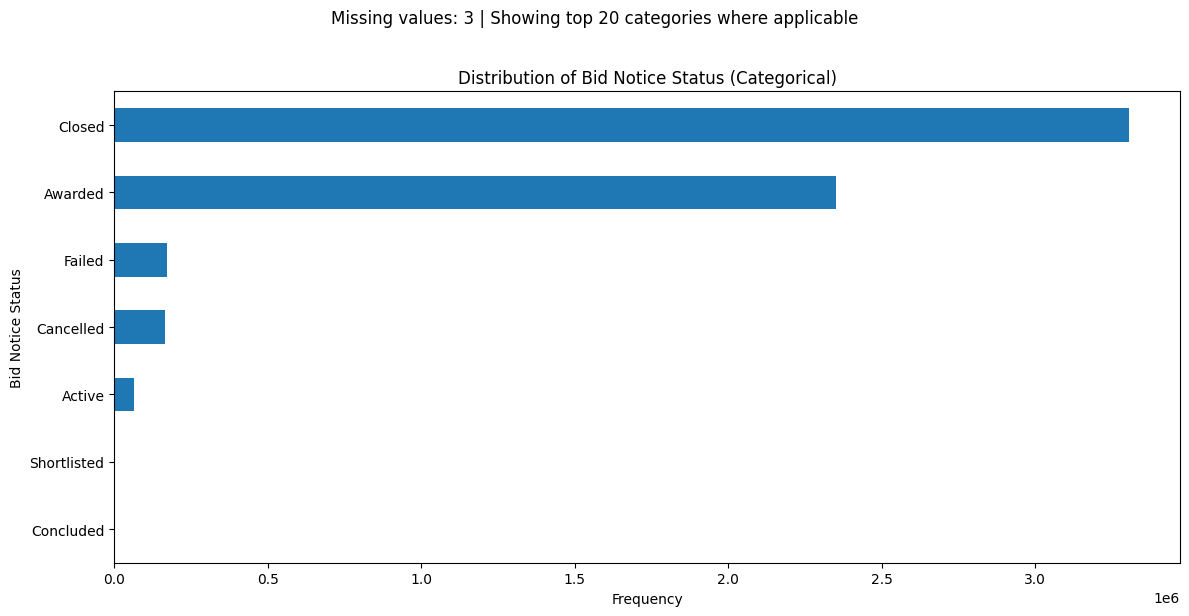

,Value,Count,Percentage (%)
0,Closed,3306308,54.57
1,Awarded,2351934,38.82
2,Failed,171009,2.82
3,Cancelled,165534,2.73
4,Active,63100,1.04
5,Shortlisted,975,0.02
6,Concluded,338,0.01
7,(Missing),3,0.0


In [5]:
plot_field = 'Bid Notice Status'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

### 5.2 One outcome per bid

In [6]:
# One label per bid. Bid references are only unique within a source system,
# so the key is (Source System, Bid Reference No.).
items = df.dropna(subset=["Bid Reference No."])
status_counts = pd.crosstab(
    [items["Source System"], items["Bid Reference No."]],
    items["Bid Notice Status"].astype("string").fillna("(missing)"),
)
n_statuses = (status_counts > 0).sum(axis=1)

bid_label = pd.Series("Other", index=status_counts.index, dtype="object")
for status in status_counts.columns:
    only_this_status = (n_statuses == 1) & (status_counts[status] > 0)
    bid_label[only_this_status] = status
bid_label[n_statuses > 1] = "Conflicting"

bid_meta = items.groupby(["Source System", "Bid Reference No."], observed=True).agg(
    procurement_mode=("Procurement Mode (Grouped)", "first"),
    published_date=("Published Date", "min"),
    line_items=("Bid Notice Status", "size"),
)
bid_meta["published_year"] = bid_meta.pop("published_date").dt.year
bids = bid_meta.join(bid_label.rename("status_label")).reset_index()

# Supervised target: 1 = failed bidding, 0 = awarded, NaN = unlabelled (ongoing, cancelled,
# closed without a posted outcome, shortlisted, missing or conflicting).
bids["Target_Failed"] = bids["status_label"].map({"Failed": 1.0, "Awarded": 0.0})

print(f"Line items with a bid reference: {len(items):,}")
print(f"Unique bids (all procurement modes): {len(bids):,}")
print(f"Line items per bid: median {bids['line_items'].median():.0f}, max {bids['line_items'].max():,}")

LABEL_ORDER = ["Awarded", "Failed", "Closed", "Cancelled", "Active", "Shortlisted",
               "Concluded", "Conflicting", "(missing)"]

def label_table(frame, by):
    table = pd.crosstab(frame["status_label"], frame[by], margins=True, margins_name="Total")
    order = [s for s in LABEL_ORDER if s in table.index] + ["Total"]
    table = table.reindex(order)
    table["Share of bids (%)"] = (table["Total"] / len(frame) * 100).round(2)
    return table

print("\nBid-level status by source system, all procurement modes:")
display(label_table(bids, "Source System"))

Line items with a bid reference: 6,059,199
Unique bids (all procurement modes): 3,620,727
Line items per bid: median 1, max 135,396

Bid-level status by source system, all procurement modes:


Source System,1.5,2.0,Total,Share of bids (%)
status_label,,,,
Awarded,1258518,16642,1275160,35.22
Failed,117368,8476,125844,3.48
Closed,2021815,32309,2054124,56.73
Cancelled,126605,23,126628,3.50
Active,31758,6301,38059,1.05
Shortlisted,831,0,831,0.02
Concluded,0,65,65,0.00
Conflicting,4,11,15,0.00
(missing),1,0,1,0.00


### 5.3 Public Bidding: observations and class balance

Public Bidding (called *Competitive Bidding (Public Bidding)* in PhilGEPS 2.0) is the modelling scope. The table and chart below give the counts a reader needs to judge the dataset: how many bids exist, how many have a usable final label, and how imbalanced the awarded/failed split is.

Public Bidding bids: 1,277,465
  labelled (Awarded or Failed): 573,643 (44.9% of Public Bidding bids)
  Awarded (Target_Failed = 0): 504,397
  Failed  (Target_Failed = 1): 69,246
  failure rate among labelled bids: 12.07%
  unlabelled (excluded from modelling): 703,822

Public Bidding bid-level status by source system:


Source System,1.5,2.0,Total,Share of bids (%)
status_label,,,,
Awarded,497139,7258,504397,39.48
Failed,64522,4724,69246,5.42
Closed,607641,9914,617555,48.34
Cancelled,60210,13,60223,4.71
Active,21220,4076,25296,1.98
Shortlisted,731,0,731,0.06
Concluded,0,13,13,0.00
Conflicting,1,3,4,0.00
Total,1251464,26001,1277465,100.00



Public Bidding by publication year:


status_label,Awarded,Failed,Closed,Cancelled,Active,Shortlisted,Concluded,Conflicting,Total bids,Label coverage (%),Failure rate among labelled (%)
published_year,,,,,,,,,,,
2023,161860,22113,145225,15359,0,250,0,0,344807,53.4,12.02
2024,181381,22268,156655,17484,8,240,0,0,378036,53.9,10.93
2025,93271,12099,185125,16025,13745,165,0,1,320431,32.9,11.48
2026,67885,12766,130550,11355,11543,76,13,3,234191,34.4,15.83


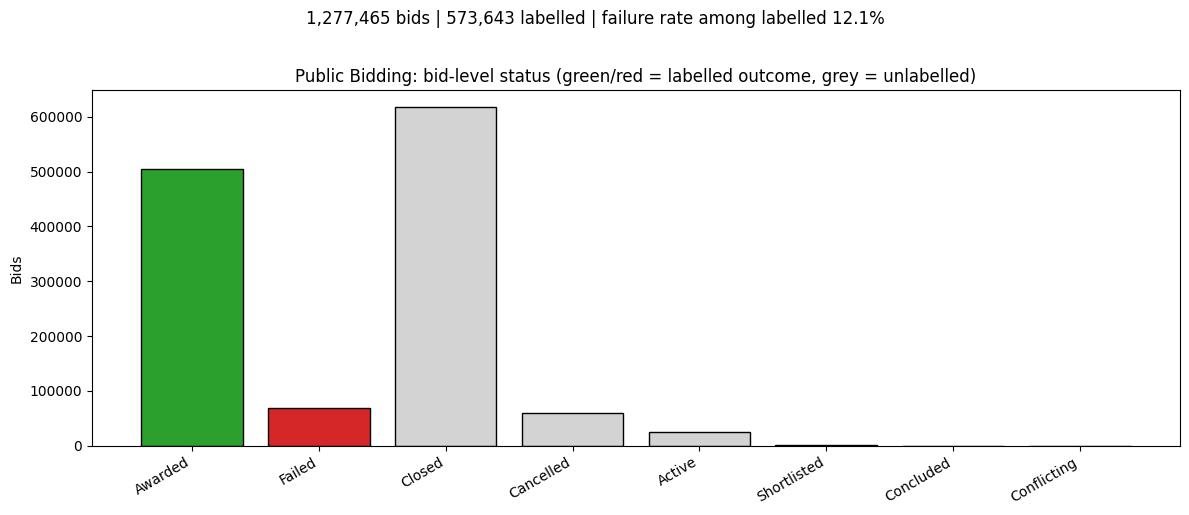

In [7]:
public = bids[bids["procurement_mode"] == "Public Bidding"].copy()
resolved = public[public["Target_Failed"].notna()]

print(f"Public Bidding bids: {len(public):,}")
print(f"  labelled (Awarded or Failed): {len(resolved):,} "
      f"({len(resolved) / len(public) * 100:.1f}% of Public Bidding bids)")
print(f"  Awarded (Target_Failed = 0): {(resolved['Target_Failed'] == 0).sum():,}")
print(f"  Failed  (Target_Failed = 1): {(resolved['Target_Failed'] == 1).sum():,}")
print(f"  failure rate among labelled bids: {resolved['Target_Failed'].mean() * 100:.2f}%")
print(f"  unlabelled (excluded from modelling): {len(public) - len(resolved):,}")

print("\nPublic Bidding bid-level status by source system:")
display(label_table(public, "Source System"))

by_year = pd.crosstab(public["published_year"], public["status_label"])
by_year = by_year[[c for c in LABEL_ORDER if c in by_year.columns]]
by_year["Total bids"] = by_year.sum(axis=1)
by_year["Label coverage (%)"] = ((by_year["Awarded"] + by_year["Failed"]) / by_year["Total bids"] * 100).round(1)
by_year["Failure rate among labelled (%)"] = (by_year["Failed"] / (by_year["Awarded"] + by_year["Failed"]) * 100).round(2)
by_year.index = by_year.index.astype(int)
print("\nPublic Bidding by publication year:")
display(by_year)

counts = public["status_label"].value_counts().reindex([s for s in LABEL_ORDER if s in public["status_label"].unique()])
colors = ["tab:green" if s == "Awarded" else "tab:red" if s == "Failed" else "lightgray" for s in counts.index]
plt.figure(figsize=(12, 5))
plt.bar(counts.index, counts.values, color=colors, edgecolor="black")
plt.ylabel("Bids")
plt.title("Public Bidding: bid-level status (green/red = labelled outcome, grey = unlabelled)")
plt.suptitle(f"{len(public):,} bids | {len(resolved):,} labelled | failure rate among labelled {resolved['Target_Failed'].mean() * 100:.1f}%", y=1.02)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
plt.close()

**Reading these numbers.** Label coverage is much lower in 2025 and 2026 than in 2023 and 2024 because many recent notices are still `Closed` or `Active` and have not reached a posted outcome. The failure rate among labelled bids is therefore conditional on a bid having a final status, and it is not the unconditional failure rate of all published notices. Both points should be stated wherever model results are presented.

## 6. Which fields are available when a notice is published?

The model must only use information that exists when the bid notice is first posted. The fields below are grouped by when they become known. Award and contract fields are **outcomes or consequences of the outcome** and must not be used as predictors. Identifiers and free text are available at publication but need separate treatment (text features or exclusion).

One caveat applies to all fields: the extracts are snapshots of each notice's final state. If an agency edited a field after publication, the extract holds the edited value. This cannot be checked from the data and should be noted as a limitation.

In [8]:
availability = {
    "Available at publication (candidate predictors)": [
        "Procuring Entity (PE)", "Region", "Province", "City/Municipality", "Government Branch",
        "PE Organization Type", "PE Organization Type (Grouped)", "Classification", "Procurement Mode",
        "Procurement Mode (Grouped)", "Business Category", "Funding Source", "Funding Instrument",
        "Trade Agreement", "Approved Budget of the Contract", "Published Date", "Closing Date",
        "Area of Delivery", "Contract Duration", "Calendar Type", "Lot Type", "Quantity", "UOM",
        "Item Budget", "UNSPSC Code",
    ],
    "Available at publication (identifiers / free text)": [
        "Bid Reference No.", "Solicitation No.", "Notice Title", "Line Item No", "Item Code",
        "Item Name", "Item Description", "UNSPSC Description",
    ],
    "Outcome (defines the target; never a predictor)": ["Bid Notice Status"],
    "Known only after bidding (exclude from predictors)": [
        "Award Reference No.", "Award Title", "Published Date(Award)", "Award Date", "Contract Amount",
        "Award Notice Status", "Notice to Proceed Date", "Contract Effectivity Date", "Contract End Date",
        "Awardee OrgID", "Awardee Organization Name", "Country of Awardee", "Region of Awardee",
        "Province of Awardee", "City/Municipality of Awardee", "Awardee Size", "Awardee Joint Venture",
    ],
    "Lineage (added by the combine script)": ["Source System", "Source File", "Source Quarter"],
}

rows = []
missing_pct = field_summary.set_index("Data Field")["Missing (%)"]
for group, fields in availability.items():
    for f in fields:
        rows.append({"Availability": group, "Data Field": f, "Missing (%)": missing_pct.get(f)})
availability_table = pd.DataFrame(rows)

unassigned = sorted(set(schema.names) - set(availability_table["Data Field"]))
assert not unassigned, f"Fields not classified: {unassigned}"
display(availability_table)

,Availability,Data Field,Missing (%)
0,Available at publication (candidate predictors),Procuring Entity (PE),0.00
1,Available at publication (candidate predictors),Region,0.00
2,Available at publication (candidate predictors),Province,0.00
3,Available at publication (candidate predictors),City/Municipality,0.00
4,Available at publication (candidate predictors),Government Branch,0.00
5,Available at publication (candidate predictors),PE Organization Type,0.00
6,Available at publication (candidate predictors),PE Organization Type (Grouped),0.00
7,Available at publication (candidate predictors),Classification,0.00
8,Available at publication (candidate predictors),Procurement Mode,0.00
9,Available at publication (candidate predictors),Procurement Mode (Grouped),0.00


## 7. Data visualizations

Charts are organised into two sections: fields with no missing values, then fields with missing values. Within each section, fields are ordered by unique-value count from fewest to most. Only fields with fewer than 100 unique values are visualised; `Bid Notice Status` was shown in section 5.

Because the dataset now combines two systems, several charts show harmonised values (for example `Region` spelling and the 2.0 statuses `Published`/`CANCEL_APPROVED` mapped to `Active`/`Cancelled`), while `Business Category`, `Funding Source` and `Award Notice Status` keep different vocabularies in PhilGEPS 1.5 and 2.0. Split by `Source System` before comparing those fields across systems.

### 1. Fields with no missing values

#### Distribution: `Source System` — 2 unique values

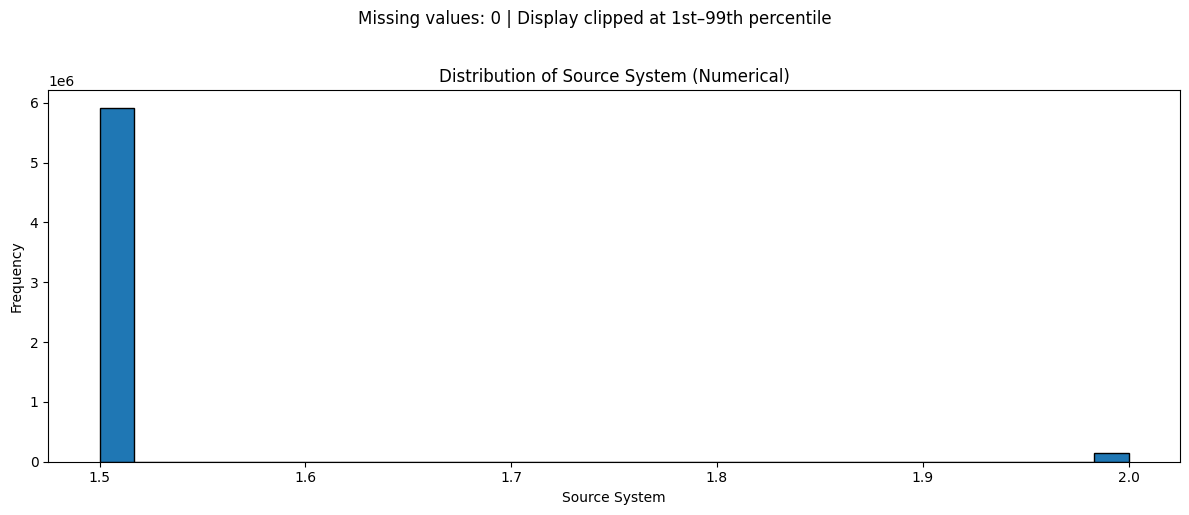

,Value,Count,Percentage (%)
0,1.5,5911134,97.56
1,2.0,148067,2.44


In [9]:
plot_field = 'Source System'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Source Quarter` — 15 unique values

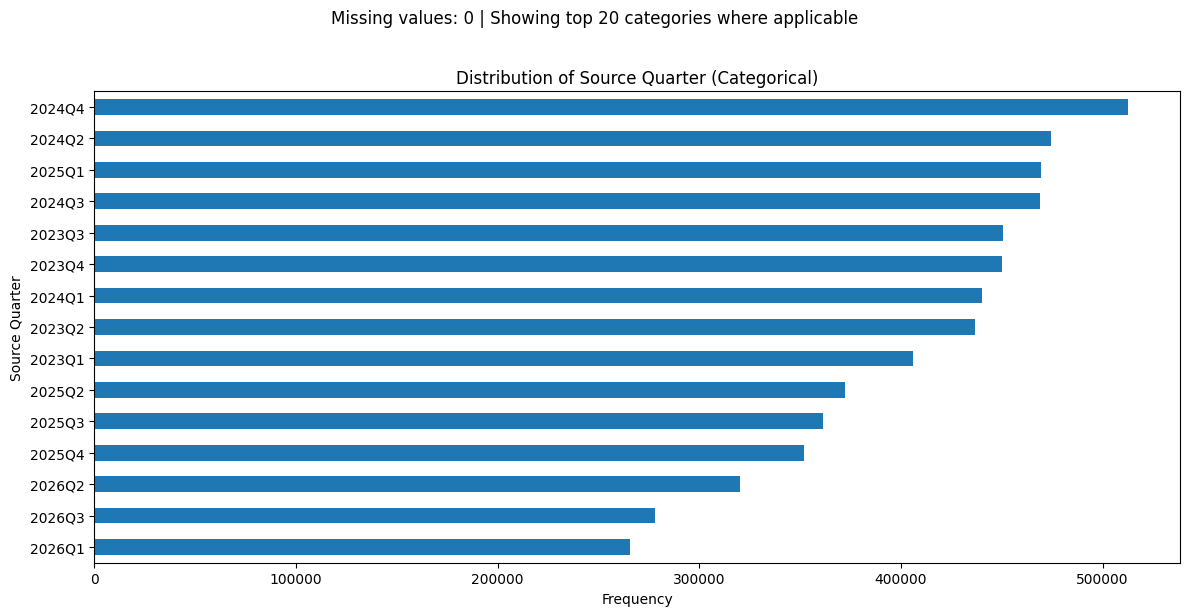

,Value,Count,Percentage (%)
0,2024Q4,512719,8.46
1,2024Q2,474381,7.83
2,2025Q1,469569,7.75
3,2024Q3,469108,7.74
4,2023Q3,450701,7.44
5,2023Q4,450311,7.43
6,2024Q1,440342,7.27
7,2023Q2,436736,7.21
8,2023Q1,405796,6.7
9,2025Q2,372122,6.14


In [10]:
plot_field = 'Source Quarter'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Source File` — 18 unique values

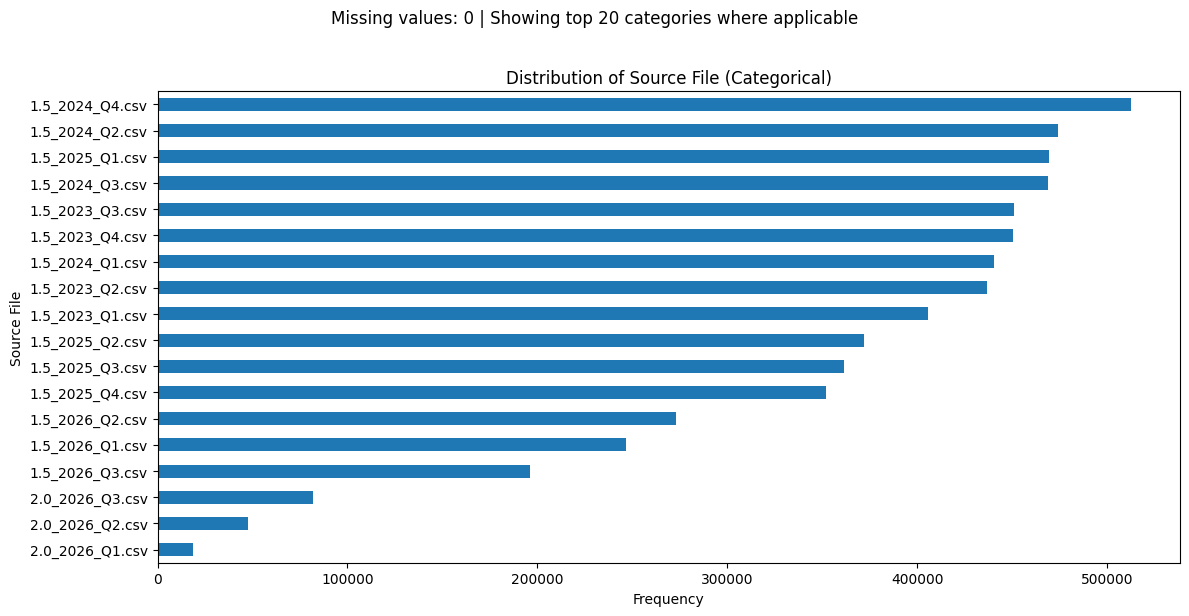

,Value,Count,Percentage (%)
0,1.5_2024_Q4.csv,512719,8.46
1,1.5_2024_Q2.csv,474381,7.83
2,1.5_2025_Q1.csv,469569,7.75
3,1.5_2024_Q3.csv,469108,7.74
4,1.5_2023_Q3.csv,450701,7.44
5,1.5_2023_Q4.csv,450311,7.43
6,1.5_2024_Q1.csv,440342,7.27
7,1.5_2023_Q2.csv,436736,7.21
8,1.5_2023_Q1.csv,405796,6.7
9,1.5_2025_Q2.csv,372122,6.14


In [11]:
plot_field = 'Source File'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

### 2. Fields with missing values

#### Distribution: `Government Branch` — 7 unique values

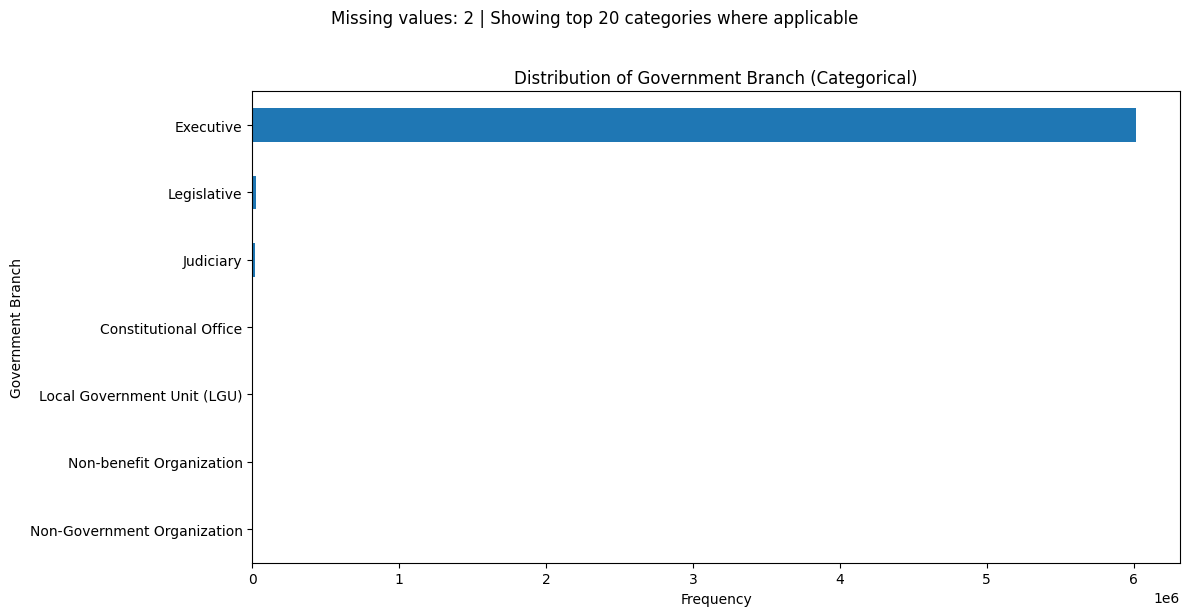

,Value,Count,Percentage (%)
0,Executive,6014990,99.27
1,Legislative,23181,0.38
2,Judiciary,17379,0.29
3,Constitutional Office,2707,0.04
4,Local Government Unit (LGU),793,0.01
5,Non-benefit Organization,82,0.0
6,Non-Government Organization,67,0.0
7,(Missing),2,0.0


In [12]:
plot_field = 'Government Branch'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Region` — 19 unique values

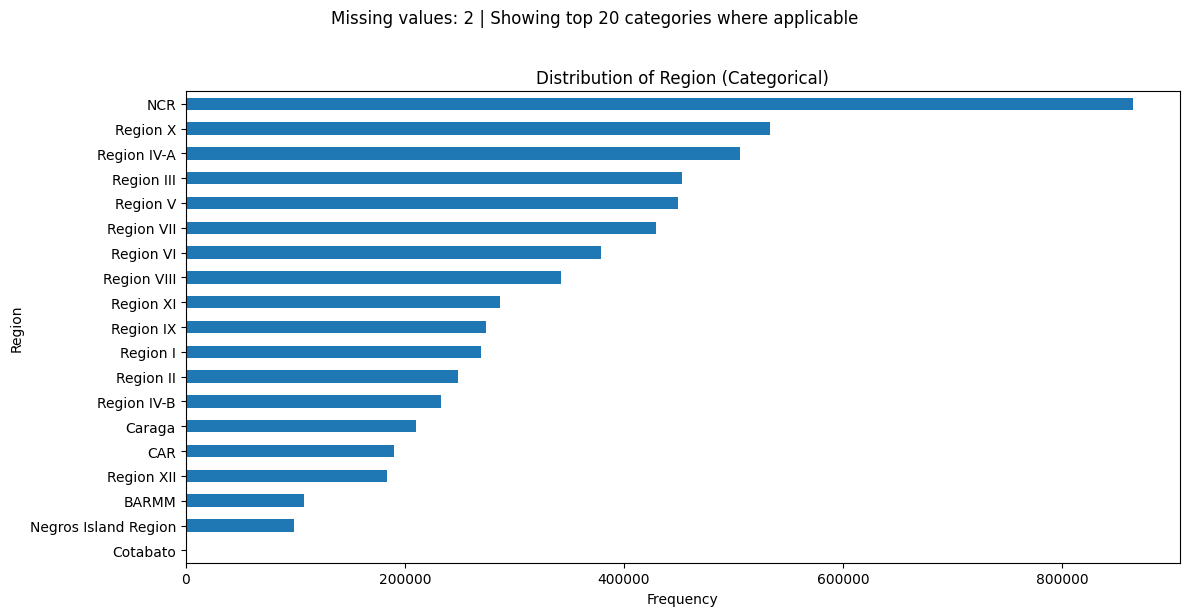

,Value,Count,Percentage (%)
0,NCR,864088,14.26
1,Region X,532981,8.8
2,Region IV-A,505611,8.34
3,Region III,452442,7.47
4,Region V,449595,7.42
5,Region VII,429290,7.08
6,Region VI,378955,6.25
7,Region VIII,342273,5.65
8,Region XI,287269,4.74
9,Region IX,273873,4.52


In [13]:
plot_field = 'Region'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Classification` — 4 unique values

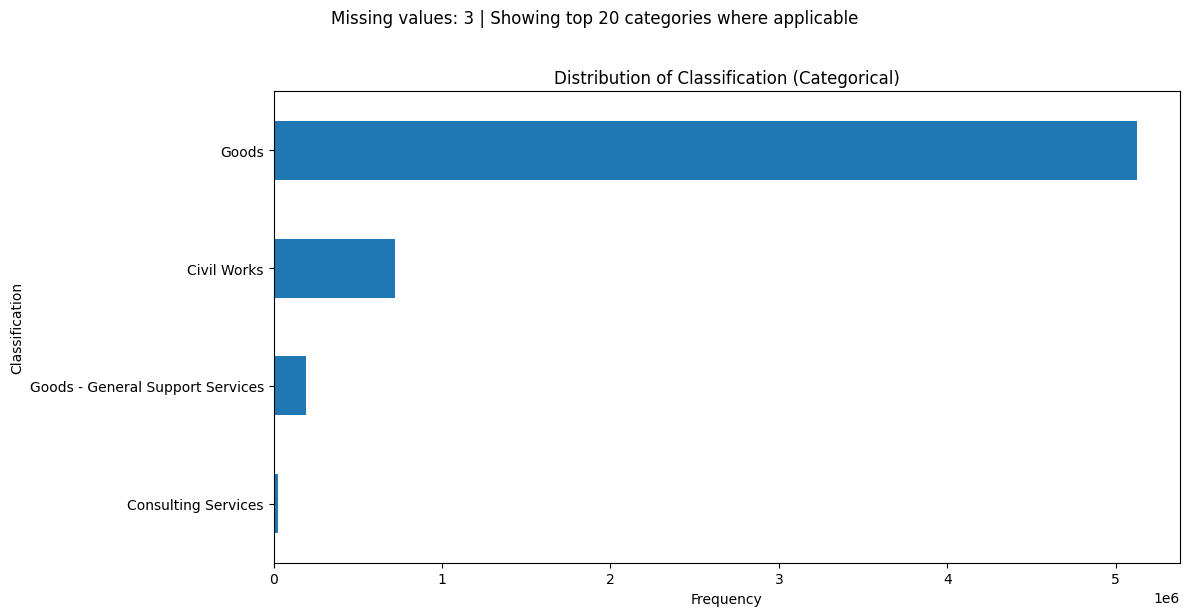

,Value,Count,Percentage (%)
0,Goods,5125249,84.59
1,Civil Works,718526,11.86
2,Goods - General Support Services,191150,3.15
3,Consulting Services,24273,0.4
4,(Missing),3,0.0


In [14]:
plot_field = 'Classification'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Trade Agreement` — 8 unique values

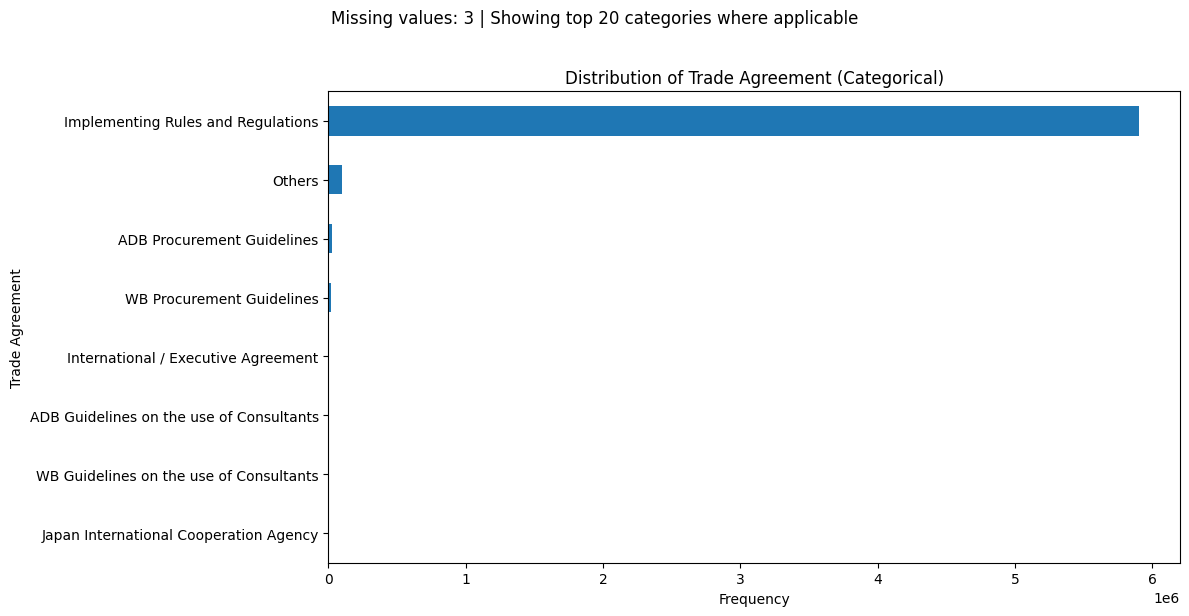

,Value,Count,Percentage (%)
0,Implementing Rules and Regulations,5907346,97.49
1,Others,101137,1.67
2,ADB Procurement Guidelines,26978,0.45
3,WB Procurement Guidelines,18575,0.31
4,International / Executive Agreement,3190,0.05
5,ADB Guidelines on the use of Consultants,1254,0.02
6,WB Guidelines on the use of Consultants,715,0.01
7,(Missing),3,0.0
8,Japan International Cooperation Agency,3,0.0


In [15]:
plot_field = 'Trade Agreement'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Funding Source` — 14 unique values

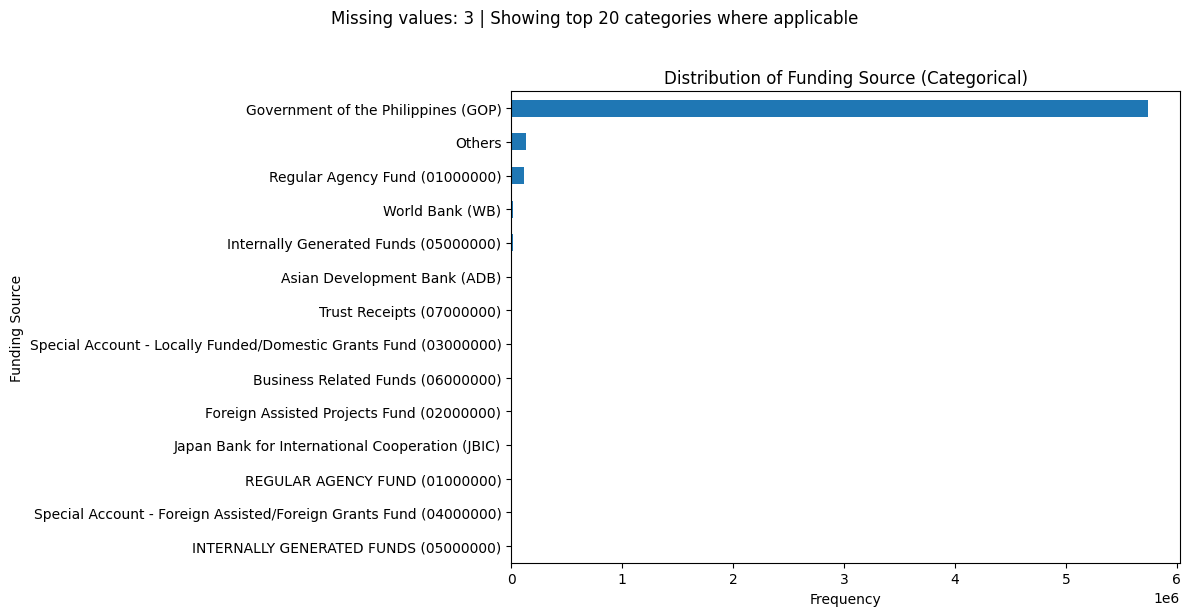

,Value,Count,Percentage (%)
0,Government of the Philippines (GOP),5741899,94.76
1,Others,136709,2.26
2,Regular Agency Fund (01000000),119451,1.97
3,World Bank (WB),20441,0.34
4,Internally Generated Funds (05000000),18195,0.3
5,Asian Development Bank (ADB),11027,0.18
6,Trust Receipts (07000000),3762,0.06
7,Special Account - Locally Funded/Domestic Grants Fund (03000000),2642,0.04
8,Business Related Funds (06000000),1756,0.03
9,Foreign Assisted Projects Fund (02000000),1570,0.03


In [16]:
plot_field = 'Funding Source'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Procurement Mode (Grouped)` — 27 unique values

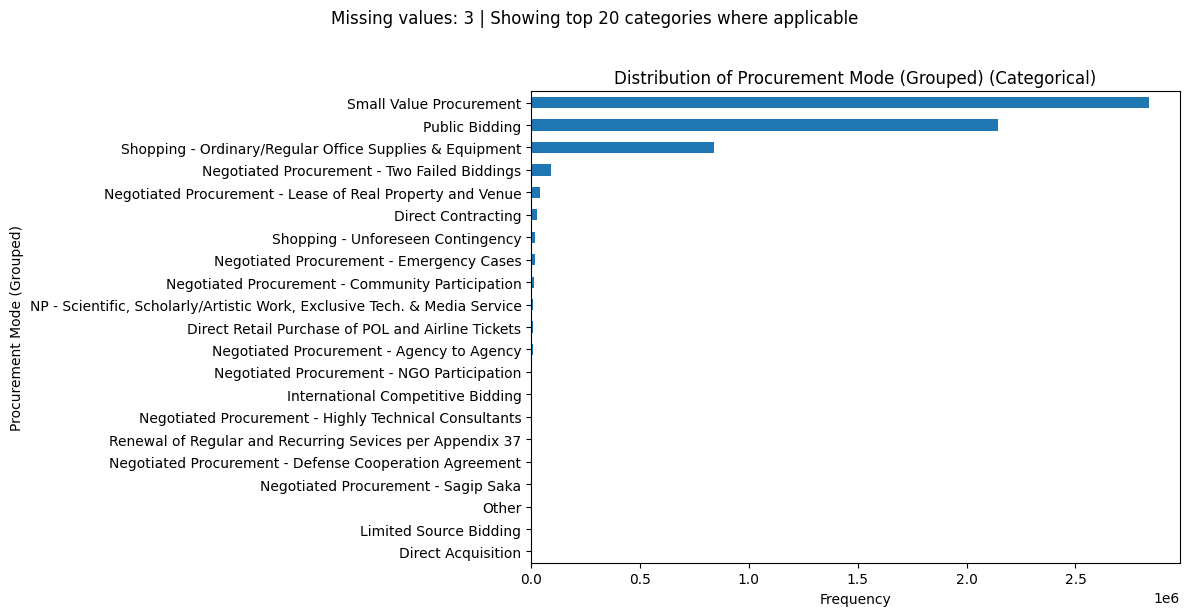

,Value,Count,Percentage (%)
0,Small Value Procurement,2838179,46.84
1,Public Bidding,2145310,35.41
2,Shopping - Ordinary/Regular Office Supplies & Equipment,839630,13.86
3,Negotiated Procurement - Two Failed Biddings,90973,1.5
4,Negotiated Procurement - Lease of Real Property and Venue,42162,0.7
5,Direct Contracting,25853,0.43
6,Shopping - Unforeseen Contingency,18235,0.3
7,Negotiated Procurement - Emergency Cases,15548,0.26
8,Negotiated Procurement - Community Participation,11180,0.18
9,"NP - Scientific, Scholarly/Artistic Work, Exclusive Tech. & Media Service",6688,0.11


In [17]:
plot_field = 'Procurement Mode (Grouped)'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Procurement Mode` — 40 unique values

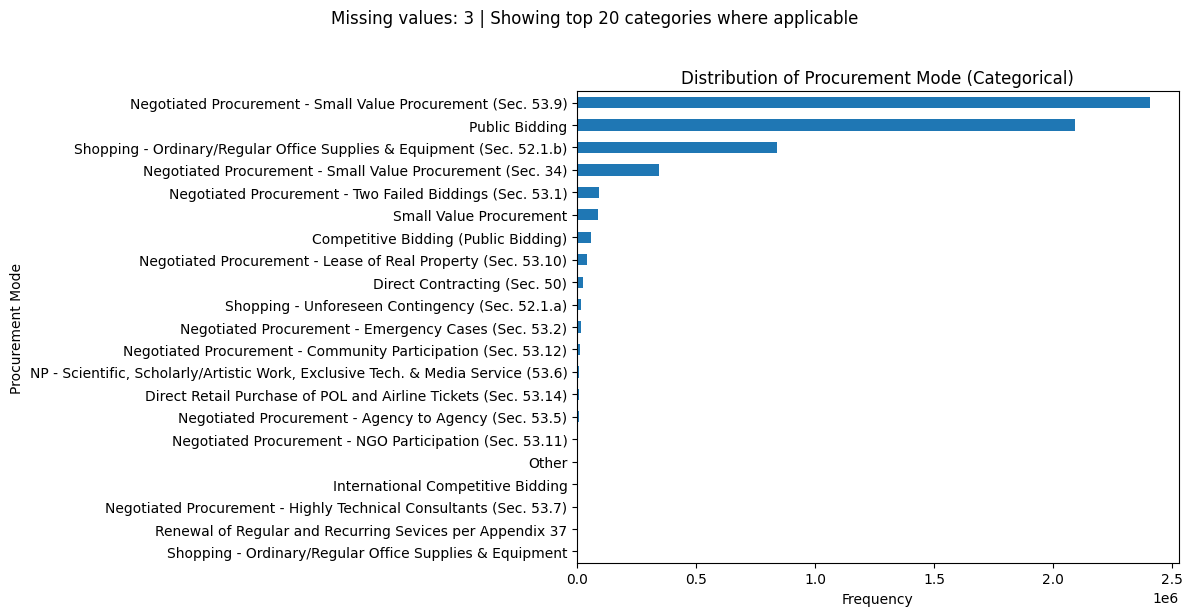

,Value,Count,Percentage (%)
0,Negotiated Procurement - Small Value Procurement (Sec. 53.9),2405407,39.7
1,Public Bidding,2089077,34.48
2,Shopping - Ordinary/Regular Office Supplies & Equipment (Sec. 52.1.b),838738,13.84
3,Negotiated Procurement - Small Value Procurement (Sec. 34),344280,5.68
4,Negotiated Procurement - Two Failed Biddings (Sec. 53.1),90445,1.49
5,Small Value Procurement,88492,1.46
6,Competitive Bidding (Public Bidding),56233,0.93
7,Negotiated Procurement - Lease of Real Property (Sec. 53.10),41492,0.68
8,Direct Contracting (Sec. 50),25732,0.42
9,Shopping - Unforeseen Contingency (Sec. 52.1.a),18235,0.3


In [18]:
plot_field = 'Procurement Mode'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `PE Organization Type (Grouped)` — 5 unique values

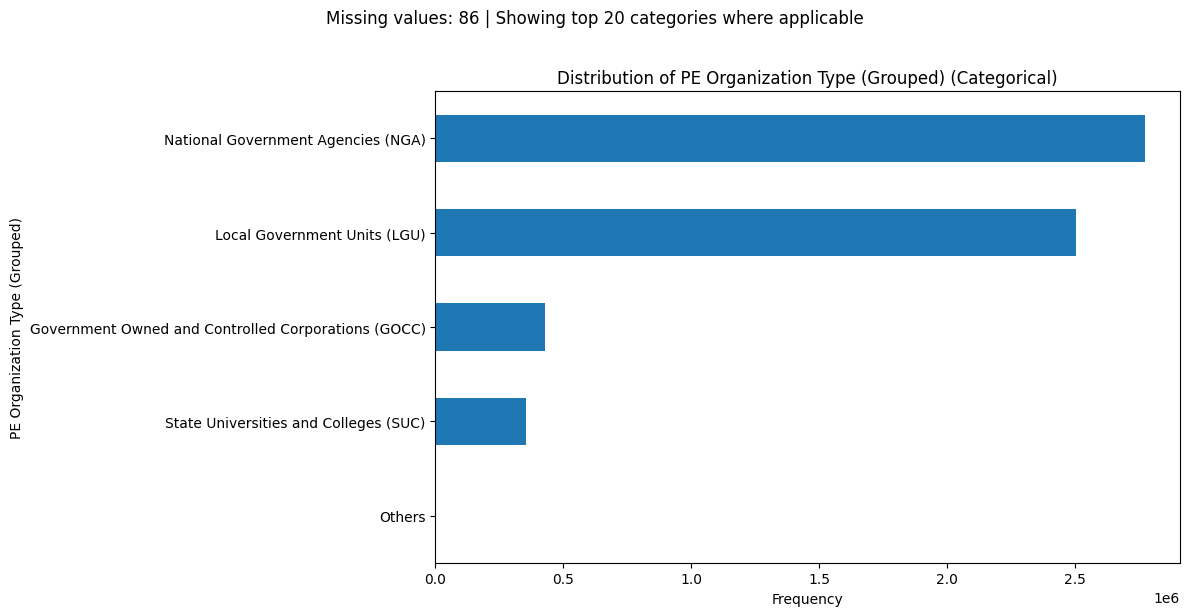

,Value,Count,Percentage (%)
0,National Government Agencies (NGA),2770884,45.73
1,Local Government Units (LGU),2503263,41.31
2,Government Owned and Controlled Corporations (GOCC),429625,7.09
3,State Universities and Colleges (SUC),355335,5.86
4,(Missing),86,0.0
5,Others,8,0.0


In [19]:
plot_field = 'PE Organization Type (Grouped)'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `PE Organization Type` — 16 unique values

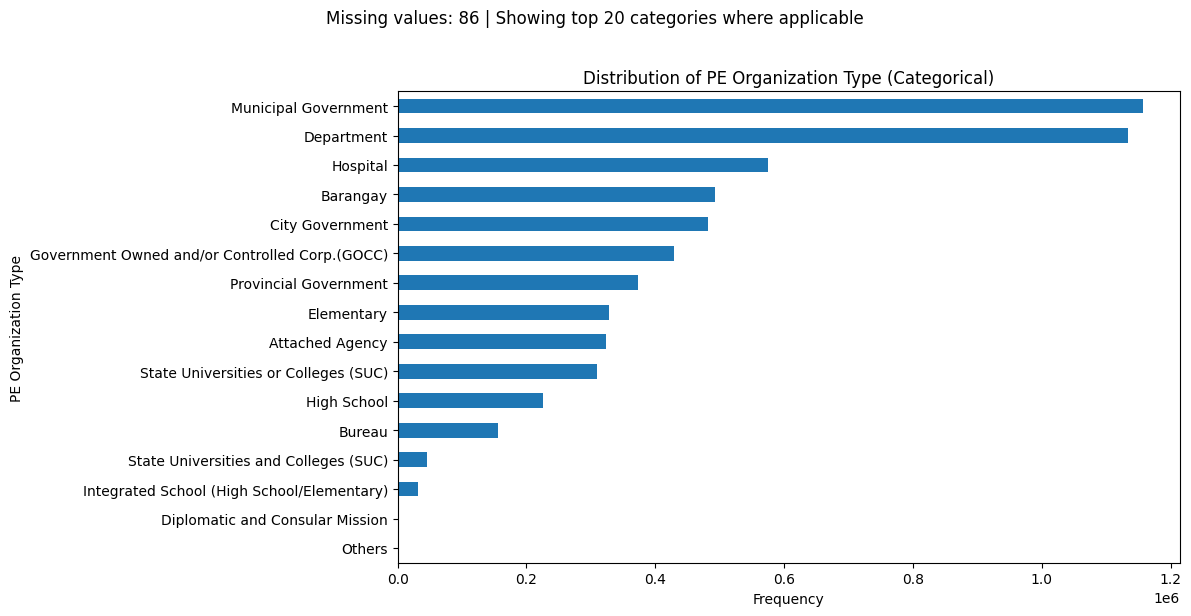

,Value,Count,Percentage (%)
0,Municipal Government,1156406,19.09
1,Department,1133000,18.7
2,Hospital,574239,9.48
3,Barangay,492380,8.13
4,City Government,481493,7.95
5,Government Owned and/or Controlled Corp.(GOCC),429625,7.09
6,Provincial Government,372984,6.16
7,Elementary,328633,5.42
8,Attached Agency,323357,5.34
9,State Universities or Colleges (SUC),309629,5.11


In [20]:
plot_field = 'PE Organization Type'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Calendar Type` — 3 unique values

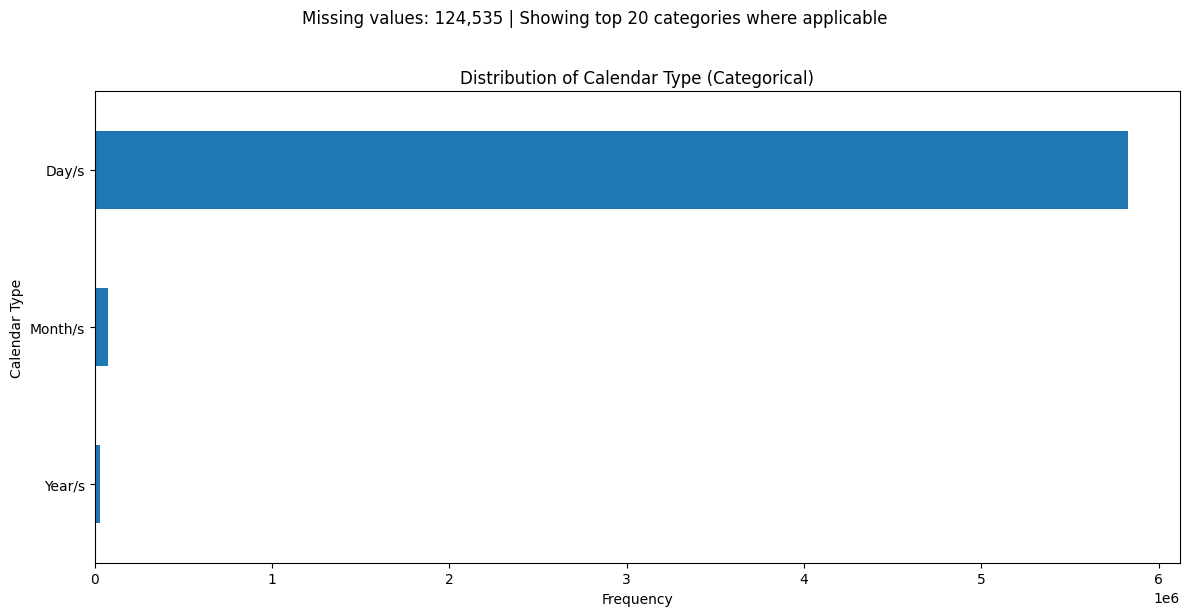

,Value,Count,Percentage (%)
0,Day/s,5827939,96.18
1,(Missing),124535,2.06
2,Month/s,74136,1.22
3,Year/s,32591,0.54


In [21]:
plot_field = 'Calendar Type'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Funding Instrument` — 6 unique values

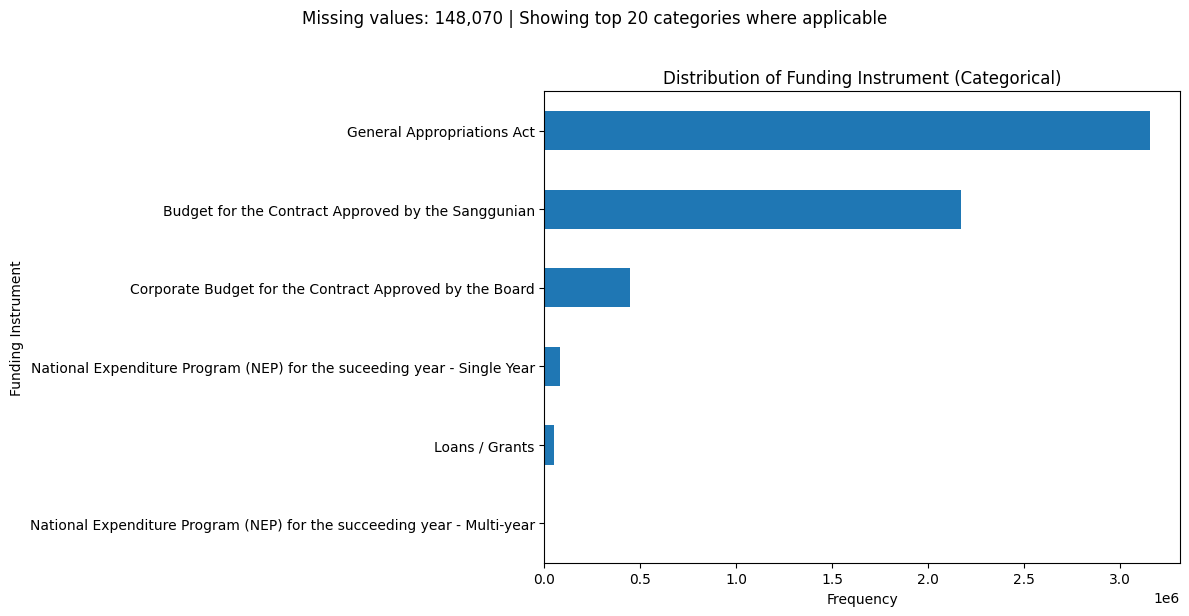

,Value,Count,Percentage (%)
0,General Appropriations Act,3157609,52.11
1,Budget for the Contract Approved by the Sanggunian,2172195,35.85
2,Corporate Budget for the Contract Approved by the Board,444722,7.34
3,(Missing),148070,2.44
4,National Expenditure Program (NEP) for the suceeding year - Single Year,83204,1.37
5,Loans / Grants,49450,0.82
6,National Expenditure Program (NEP) for the succeeding year - Multi-year,3951,0.07


In [22]:
plot_field = 'Funding Instrument'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `UOM` — 66 unique values

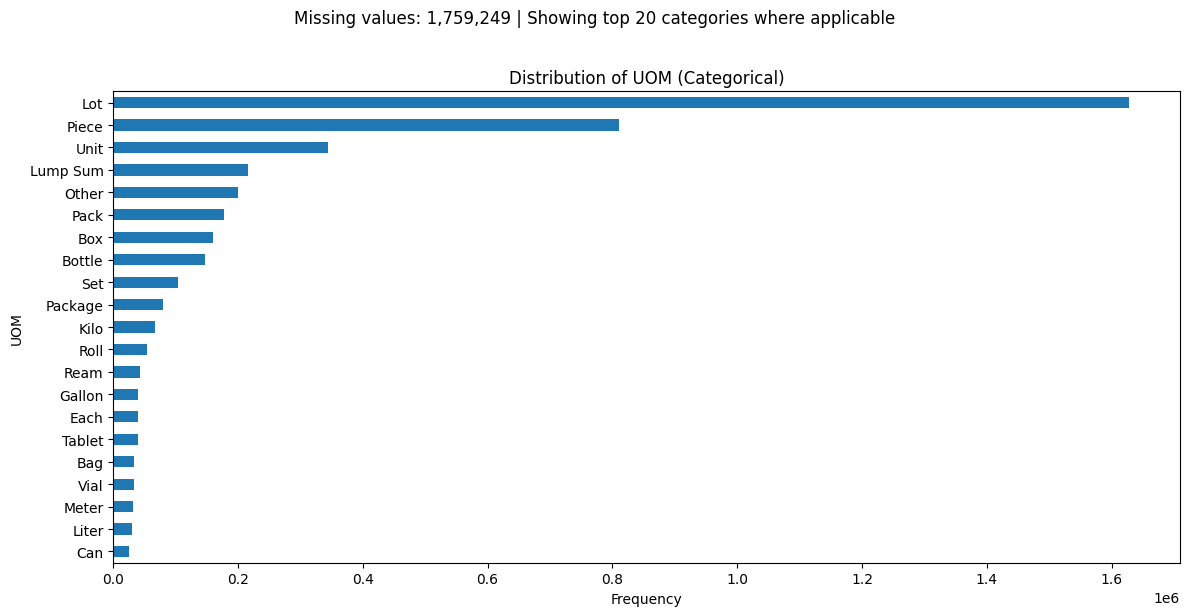

,Value,Count,Percentage (%)
0,(Missing),1759249,29.03
1,Lot,1628333,26.87
2,Piece,810002,13.37
3,Unit,344546,5.69
4,Lump Sum,216634,3.58
5,Pack,176703,2.92
6,Box,159231,2.63
7,Bottle,147159,2.43
8,Set,102978,1.7
9,Package,79259,1.31


In [23]:
plot_field = 'UOM'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Award Notice Status` — 7 unique values

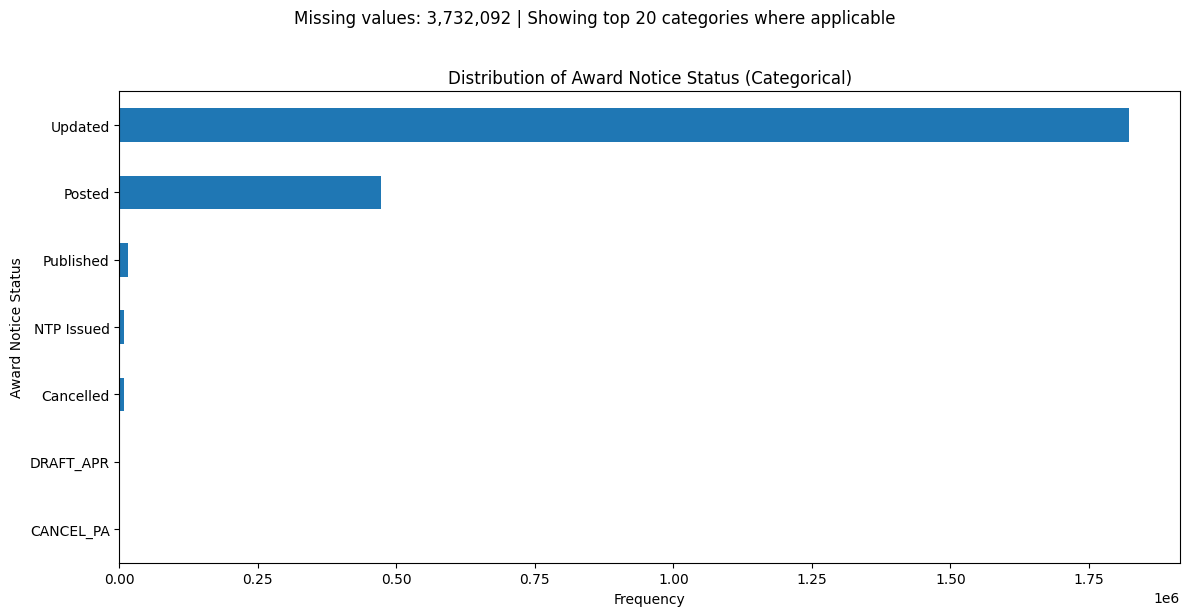

,Value,Count,Percentage (%)
0,(Missing),3732092,61.59
1,Updated,1823133,30.09
2,Posted,472342,7.8
3,Published,15421,0.25
4,NTP Issued,8203,0.14
5,Cancelled,7951,0.13
6,DRAFT_APR,58,0.0
7,CANCEL_PA,1,0.0


In [24]:
plot_field = 'Award Notice Status'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Country of Awardee` — 41 unique values

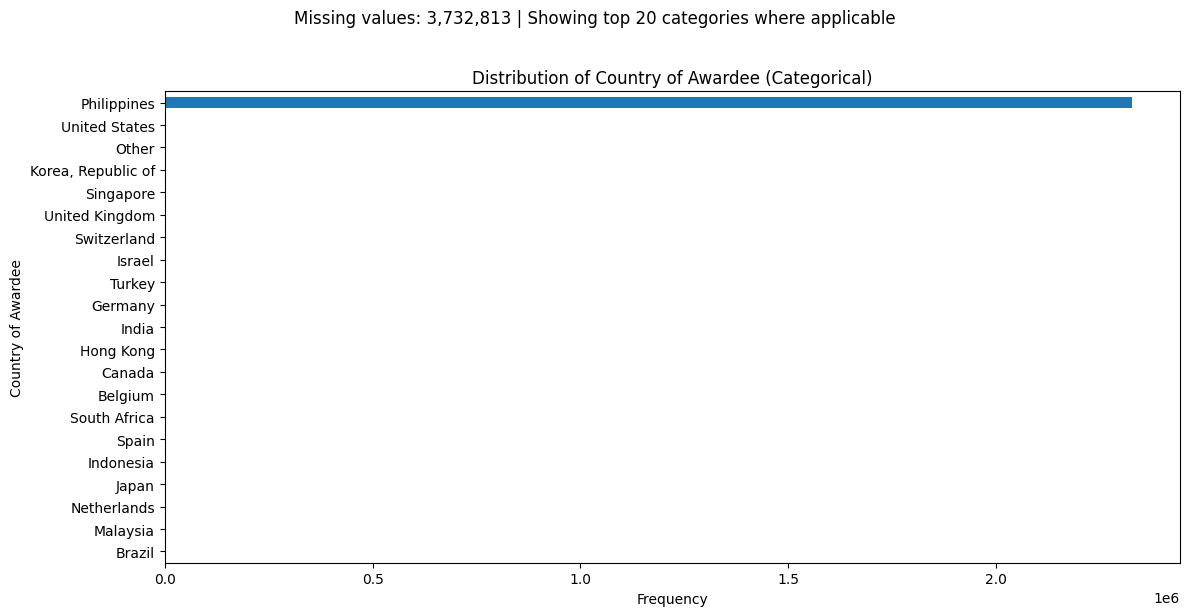

,Value,Count,Percentage (%)
0,(Missing),3732813,61.61
1,Philippines,2325388,38.38
2,United States,437,0.01
3,"Korea, Republic of",75,0.0
4,Singapore,67,0.0
5,United Kingdom,65,0.0
6,Switzerland,43,0.0
7,Israel,36,0.0
8,Turkey,27,0.0
9,Germany,23,0.0


In [25]:
plot_field = 'Country of Awardee'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Province of Awardee` — 86 unique values

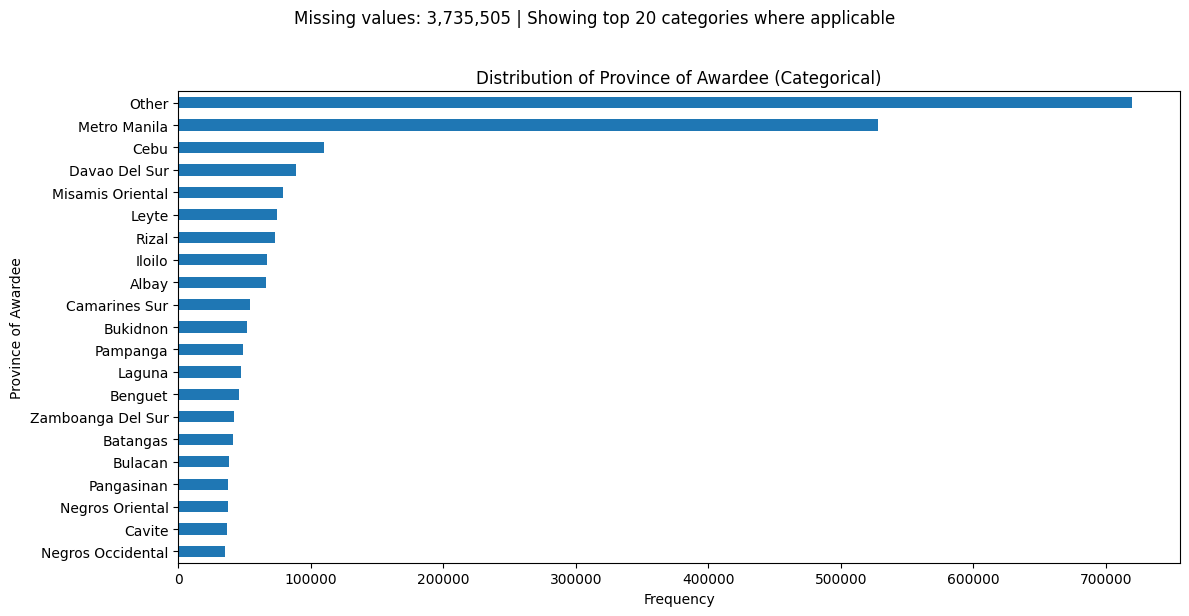

,Value,Count,Percentage (%)
0,(Missing),3735505,61.65
1,Metro Manila,528202,8.72
2,Cebu,109684,1.81
3,Davao Del Sur,88624,1.46
4,Misamis Oriental,78766,1.3
5,Leyte,74757,1.23
6,Rizal,72992,1.2
7,Iloilo,67077,1.11
8,Albay,66453,1.1
9,Camarines Sur,54451,0.9


In [26]:
plot_field = 'Province of Awardee'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Region of Awardee` — 18 unique values

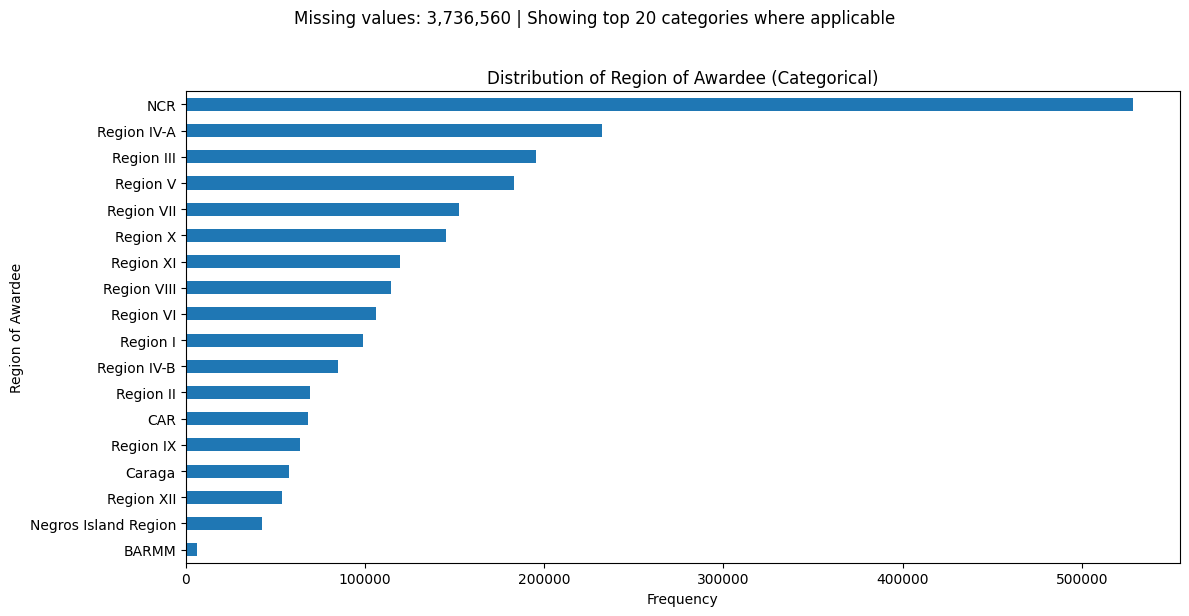

,Value,Count,Percentage (%)
0,(Missing),3736560,61.67
1,NCR,528218,8.72
2,Region IV-A,232153,3.83
3,Region III,195247,3.22
4,Region V,183376,3.03
5,Region VII,152337,2.51
6,Region X,145381,2.4
7,Region XI,119591,1.97
8,Region VIII,114666,1.89
9,Region VI,105949,1.75


In [27]:
plot_field = 'Region of Awardee'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Awardee Size` — 4 unique values

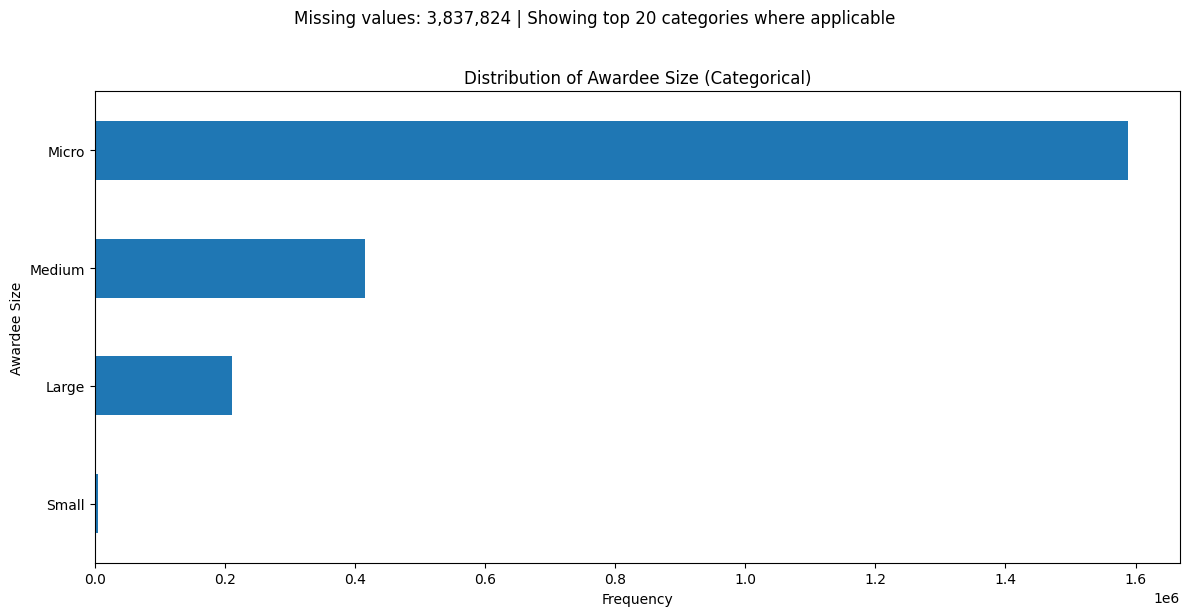

,Value,Count,Percentage (%)
0,(Missing),3837824,63.34
1,Micro,1588856,26.22
2,Medium,416117,6.87
3,Large,211139,3.48
4,Small,5265,0.09


In [28]:
plot_field = 'Awardee Size'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

#### Distribution: `Lot Type` — 2 unique values

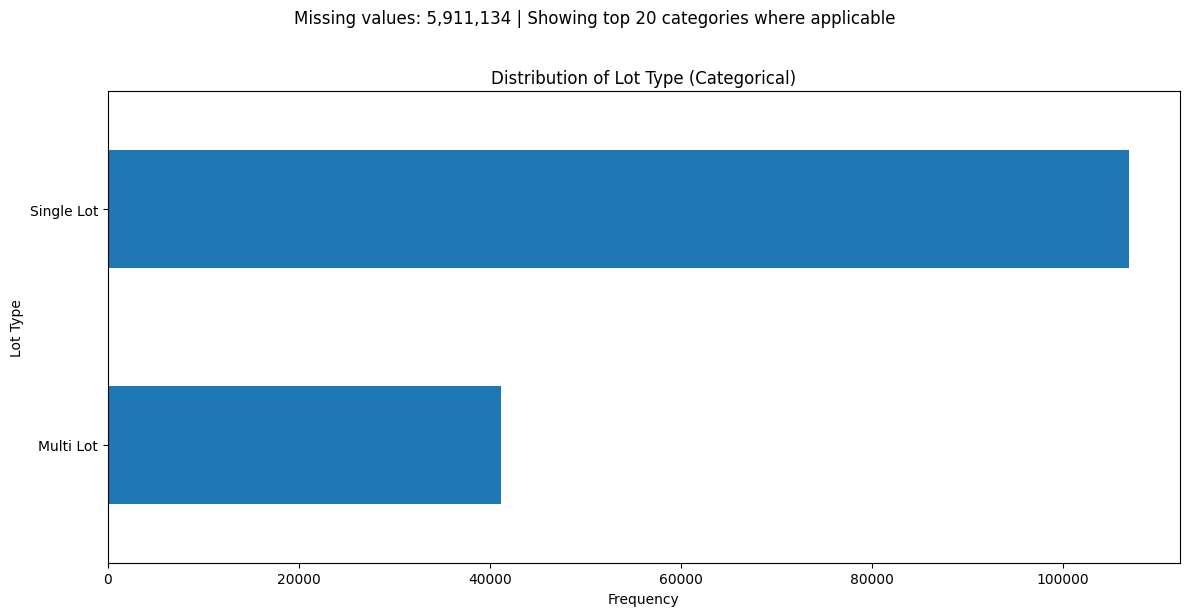

,Value,Count,Percentage (%)
0,(Missing),5911134,97.56
1,Single Lot,106888,1.76
2,Multi Lot,41179,0.68


In [29]:
plot_field = 'Lot Type'

if plot_field not in df.columns:
    print(f"Field not found in dataset: {plot_field}")
else:
    series = df[plot_field]


    missing_count = series.isna().sum()

    # Infer the chart type within this cell (no separate classification section).
    name_lower = plot_field.lower()
    identifier_keywords = ["reference no", "line item no", "unspsc", "code", " id"]

    if "date" in name_lower:
        field_type = "Date"
    elif any(keyword in name_lower for keyword in identifier_keywords):
        field_type = "Categorical / Identifier"
    else:
        non_missing = series.dropna().astype("string").str.strip()
        numeric_values = pd.to_numeric(
            non_missing.str.replace(",", "", regex=False),
            errors="coerce"
        )
        numeric_ratio = numeric_values.notna().mean() if len(non_missing) else 0
        field_type = "Numerical" if numeric_ratio >= 0.90 else "Categorical"

    if field_type == "Numerical":
        values = pd.to_numeric(
            series.astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        ).dropna()

        if values.empty:
            print(f"No numeric values to plot: {plot_field}")
        else:
            lower, upper = values.quantile([0.01, 0.99])
            chart_values = values.clip(lower=lower, upper=upper)
            plt.figure(figsize=(12, 5))
            plt.hist(chart_values, bins=30, edgecolor="black")
            plt.xlabel(plot_field)
            plt.ylabel("Frequency")
            plt.title(f"Distribution of {plot_field} (Numerical)")
            plt.suptitle(f"Missing values: {missing_count:,} | Display clipped at 1st–99th percentile", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    elif field_type == "Date":
        dates = pd.to_datetime(series, errors="coerce")
        valid_dates = dates.dropna()

        if valid_dates.empty:
            print(f"No parseable dates to plot: {plot_field}")
        else:
            monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
            monthly_counts.index = monthly_counts.index.astype(str)
            plt.figure(figsize=(12, 5))
            monthly_counts.plot(kind="bar")
            plt.xlabel("Month")
            plt.ylabel("Frequency")
            plt.title(f"Monthly Distribution of {plot_field}")
            plt.suptitle(f"Missing values: {missing_count:,}", y=1.02)
            plt.xticks(rotation=60, ha="right")
            plt.tight_layout()
            plt.show()
            plt.close()

    else:
        counts = series.dropna().astype("string").value_counts()

        if counts.empty:
            print(f"No non-missing values to plot: {plot_field}")
        else:
            top_n = 20
            if len(counts) > top_n:
                counts_to_plot = counts.iloc[:top_n].copy()
                other_count = counts.iloc[top_n:].sum()
                if other_count > 0:
                    counts_to_plot.loc["Other"] = other_count
            else:
                counts_to_plot = counts.copy()

            plt.figure(figsize=(12, 6))
            counts_to_plot.sort_values().plot(kind="barh")
            plt.xlabel("Frequency")
            plt.ylabel(plot_field)
            plt.title(f"Distribution of {plot_field} ({field_type})")
            plt.suptitle(f"Missing values: {missing_count:,} | Showing top 20 categories where applicable", y=1.02)
            plt.tight_layout()
            plt.show()
            plt.close()

    # Frequency table: count and percentage for every value, including missing values.
    frequency_values = series.astype("string").fillna("(Missing)")
    frequency_table = (
        frequency_values.value_counts(dropna=False)
        .rename_axis("Value")
        .reset_index(name="Count")
    )
    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(series) * 100
    ).round(2)
    display(frequency_table)

## 8. Optional: export the bid-level outcome table and the field summary

Uncomment the lines below to save the bid-level table (one row per bid with `Target_Failed`) and the field summary. Files in `data/processed/` are ignored by Git.

In [30]:
# OUTPUT_FOLDER = Path("data") / "processed"
# OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
#
# bids.to_parquet(OUTPUT_FOLDER / "philgeps_bid_labels.parquet", index=False)
# field_summary.to_csv(OUTPUT_FOLDER / "philgeps_field_summary.csv", index=False)
#
# print("Files exported to:", OUTPUT_FOLDER.resolve())